# 02 — Data preparation: cleaning, labels, features

*CRISP-DM phase 3 · code: `src/sp500/data_prep.py`, `labels.py`, `features.py`, `process_data.py`*

Turns the raw CSV snapshot into two tables:

- `sp500_daily`: the 5 series cleaned and aligned on one trading calendar;
- `model_table`: features (known at the close of day *t*), regime labels and forward targets.

It then runs the automatic checks (including a no-look-ahead test) and saves everything to `data/processed/`.

← previous: [`01_data_understanding.ipynb`](01_data_understanding.ipynb) · next: [`03_eda.ipynb`](03_eda.ipynb) →

In [1]:
import sys, warnings
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path[:0] = [str(ROOT / "src"), str(ROOT)]   # project package + root scripts

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 100, "axes.titleweight": "bold", "font.size": 10})

In [2]:
import process_data as pdp
from sp500.config import HORIZONS, DATA_PROCESSED, REPORTS
from sp500.data_prep import build_dataset
from sp500.features import build_model_table
from sp500.labels import episodes

## 1. Clean and align the raw series

Non-positive prices are removed, the fake pre-1962 open/high/low of `^GSPC` are blanked, short calendar gaps (≤ 2 days) are forward-filled, and one-day spikes that fully reverse (bad prints) are repaired.

In [3]:
daily, quality = build_dataset()
print(f"sp500_daily: {daily.shape[0]:,} rows x {daily.shape[1]} columns, {daily.index.min().date()} -> {daily.index.max().date()}")
quality

[fix] 4 suspected bad prints in gspc_close replaced: 1935-04-16, 1935-08-16, 1936-09-16, 1961-04-17
sp500_daily: 24,821 rows x 32 columns, 1927-12-30 -> 2026-10-23


,series,rows,start,end,non_positive_prices,flat_ohlc_rows,inconsistent_hlc_rows,zero_volume_rows,missing_close,moves_gt_15pct,largest_up_move,largest_down_move,largest_down_date,bad_prints_fixed
0,gspc,24821,1927-12-30,2026-10-23,0,8547,0,5497,0,2,0.153661,-0.228997,1987-10-19,4
1,sp500tr,9776,1988-01-04,2026-10-23,0,5379,0,9776,0,0,0.109582,-0.127605,2020-03-16,0
2,spy,8492,1993-01-29,2026-10-23,0,0,0,0,0,0,0.135577,-0.115887,2020-03-16,0
3,es,6590,2000-09-18,2026-10-23,0,0,10,11,0,0,0.132022,-0.109552,2020-03-16,0
4,vix,9273,1990-01-02,2026-10-23,0,508,0,9273,0,321,0.768245,-0.442449,2025-04-09,0


In [4]:
daily.tail()

,gspc_open,gspc_high,gspc_low,gspc_close,gspc_adj_close,gspc_volume,sp500tr_open,sp500tr_high,sp500tr_low,sp500tr_close,sp500tr_adj_close,sp500tr_volume,spy_open,spy_high,spy_low,spy_close,spy_adj_close,spy_volume,es_open,es_high,es_low,es_close,es_adj_close,es_volume,vix_open,vix_high,vix_low,vix_close,vix_adj_close,vix_volume,gspc_bad_print_fixed,es_roll_window
date,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2026-10-19,7702.7700,7731.1802,7684.7900,7690.7300,7690.7300,4.587260e+09,17283.2695,17346.9297,17243.0000,17256.2402,17256.2402,NaN,767.23,770.46,765.82,766.48,766.48,38680100.0,7679.50,7773.25,7677.00,7734.50,7734.50,1740657.0,18.37,18.93,17.39,18.44,18.44,NaN,0,0
2026-10-20,7679.0098,7748.4199,7668.0298,7712.5698,7712.5698,5.004770e+09,17230.0996,17385.8594,17205.4805,17305.4102,17305.4102,NaN,765.86,772.29,764.25,769.05,769.05,35048400.0,7740.75,7791.50,7704.50,7755.25,7755.25,1718580.0,18.42,19.13,17.25,17.31,17.31,NaN,0,0
2026-10-21,7736.4302,7770.3999,7709.3398,7757.1699,7757.1699,4.921480e+09,17359.1406,17434.8301,17298.3594,17405.6797,17405.6797,NaN,771.17,774.44,768.40,773.09,773.09,31943800.0,7785.00,7812.25,7751.00,7800.25,7800.25,1680253.0,17.25,17.58,16.51,16.68,16.68,NaN,0,0
2026-10-22,7694.6201,7702.9399,7637.3599,7663.4302,7663.4302,5.972620e+09,17265.5703,17282.4707,17137.2891,17195.5703,17195.5703,NaN,766.37,767.71,761.17,763.96,763.96,54117100.0,7797.00,7798.75,7676.75,7704.50,7704.50,2274209.0,18.29,20.31,17.71,19.03,19.03,NaN,0,1
2026-10-23,7637.1802,7660.1499,7612.0698,7623.6802,7623.6802,5.062330e+09,17137.3594,17187.5098,17081.2695,17107.0605,17107.0605,NaN,759.90,763.47,758.68,759.97,759.97,33377700.0,7706.25,7714.25,7648.50,7659.75,7659.75,1744080.0,19.18,20.66,18.87,19.45,19.45,NaN,0,1


## 2. Labels, targets and features

- **Bull / bear**: 20% peak-to-trough rule (hindsight → label only) + a merged robustness label.
- **Calm / stressed**: 21-day realized vol above the 80th percentile of the previous 5 years (causal) + a fixed 25% robustness label.
- **Targets**: the label shifted *forward* by *h* = 5 and 21 days. Features are never shifted backward.

In [5]:
table = build_model_table(daily, horizons=list(HORIZONS))
label_cols = set(pdp.ALL_LABELS) | {"stress_threshold"}
feature_cols = [c for c in table.columns if c not in label_cols and not c.startswith("target_")]
print(f"model_table: {table.shape[0]:,} rows x {table.shape[1]} columns, {len(feature_cols)} features")
pd.DataFrame({"first valid date": table[feature_cols].apply(lambda s: s.first_valid_index().date())}).T

model_table: 24,821 rows x 34 columns, 20 features


,ret_1d,mom_1m,mom_3m,mom_6m,mom_12m,dist_ma50,dist_ma200,drawdown,rv_21d,rv_63d,parkinson_21d,garman_klass_21d,gap_open,spy_vol_ratio_20d,vix,vix_rv_spread,vix_chg_5d,es_ret_1d,below_peak_regime,rv_vs_5y_p80
first valid date,1928-01-03,1928-01-31,1928-04-02,1928-07-02,1929-01-03,1928-03-13,1928-10-16,1927-12-30,1928-01-31,1928-04-02,1962-01-30,1962-01-30,1962-01-02,1993-02-26,1990-01-02,1990-01-02,1990-01-09,2000-09-19,1927-12-30,1933-02-10


In [6]:
share = table[list(pdp.ALL_LABELS)].mean().rename("share of days")
share.to_frame().style.format("{:.1%}")

,share of days
bear,20.9%
bear_merged,23.6%
bear_recovery,50.6%
stressed,22.0%
stressed_fixed,11.7%


In [7]:
bears = episodes(table["bear"])
bears["fall_pct"] = [daily["gspc_close"].loc[a:b].min() / daily["gspc_close"].loc[a] - 1 for a, b in zip(bears.start, bears.end)]
bears.style.format({"fall_pct": "{:.1%}"})

,start,end,days,fall_pct
0,1929-09-16 00:00:00,1929-11-13 00:00:00,41,-44.6%
1,1930-04-10 00:00:00,1930-12-16 00:00:00,172,-44.3%
2,1931-02-24 00:00:00,1931-06-02 00:00:00,70,-32.9%
3,1931-06-26 00:00:00,1931-10-05 00:00:00,71,-42.5%
4,1931-11-09 00:00:00,1932-06-01 00:00:00,141,-61.8%
5,1932-09-07 00:00:00,1933-02-27 00:00:00,117,-40.6%
6,1933-07-18 00:00:00,1933-10-19 00:00:00,66,-29.4%
7,1934-02-06 00:00:00,1935-03-14 00:00:00,274,-31.8%
8,1937-03-10 00:00:00,1938-03-31 00:00:00,268,-54.5%
9,1938-10-10 00:00:00,1939-04-11 00:00:00,123,-25.1%


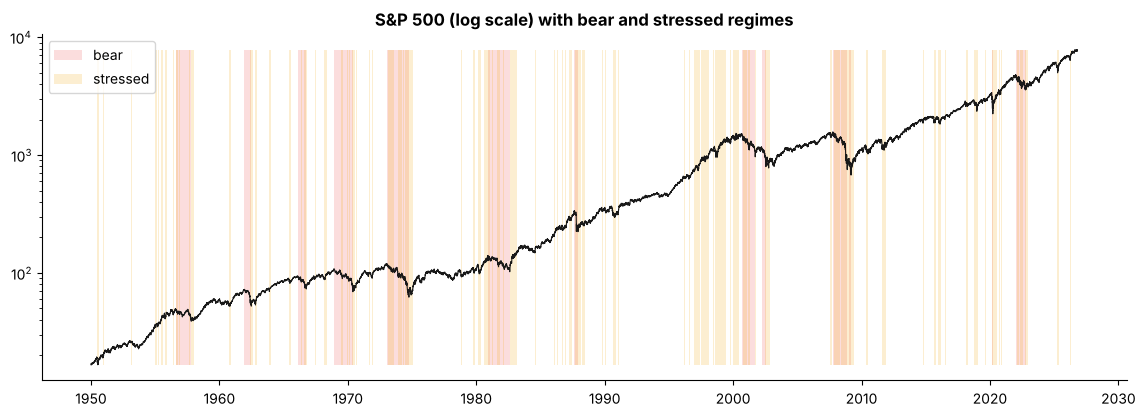

In [8]:
fig, ax = plt.subplots(figsize=(14, 4.5))
px = daily["gspc_close"].loc["1950":]
ax.semilogy(px.index, px, color="#191919", lw=0.8)
b = table["bear"].loc["1950":].fillna(0).astype(bool)
s = table["stressed"].loc["1950":].fillna(0).astype(bool)
ax.fill_between(px.index, px.min(), px.max(), where=b.reindex(px.index, fill_value=False), color="#ec4647", alpha=0.18, lw=0, label="bear")
ax.fill_between(px.index, px.min(), px.max(), where=s.reindex(px.index, fill_value=False), color="#f2a600", alpha=0.18, lw=0, label="stressed")
ax.set_title("S&P 500 (log scale) with bear and stressed regimes")
ax.legend(loc="upper left"); ax.spines[["top", "right"]].set_visible(False)
plt.show()

## 3. Automatic checks

Includes a **no-look-ahead test**: features rebuilt on data truncated at a past date must equal the features of the full build.

In [9]:
checks = pdp.run_checks(table, daily, list(HORIZONS))
chk = pd.DataFrame(checks, columns=["check", "status", "detail"])
print(chk["status"].value_counts().to_string())
chk

status
PASS    46
WARN     6


,check,status,detail
0,target_bear_h5 == bear.shift(-5),PASS,
1,target_bear_h5 is NaN in the last 5 rows,PASS,
2,target_bear_merged_h5 == bear_merged.shift(-5),PASS,
3,target_bear_merged_h5 is NaN in the last 5 rows,PASS,
4,target_stressed_h5 == stressed.shift(-5),PASS,
5,target_stressed_h5 is NaN in the last 5 rows,PASS,
6,target_stressed_fixed_h5 == stressed_fixed.shi...,PASS,
7,target_stressed_fixed_h5 is NaN in the last 5 ...,PASS,
8,target_bear_h21 == bear.shift(-21),PASS,
9,target_bear_h21 is NaN in the last 21 rows,PASS,


## 4. Save

In [10]:
written = pdp.save(daily, "sp500_daily", "both") + pdp.save(table, "model_table", "both")
quality.round(4).to_csv(REPORTS / "data_quality.csv", index=False)
pdp.write_summary(REPORTS / "processing_summary.md", daily, table, quality.round(4), checks, list(HORIZONS), feature_cols)
for path in written:
    print(path.relative_to(ROOT), f"{path.stat().st_size / 1e6:.1f} MB")

data/processed/sp500_daily.csv 2.9 MB
data/processed/sp500_daily.parquet 1.7 MB
data/processed/model_table.csv 4.8 MB
data/processed/model_table.parquet 3.6 MB


**Result.** All checks pass (warnings are documented known issues). Next: exploratory analysis in [`03_eda.ipynb`](03_eda.ipynb).